In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Aufgabe 1: Bestimmung der Tonhöhe eines akustischen Signals

Einlesen der Messdaten

In [3]:
data = pd.read_csv(
    "data/ton2.csv",
    sep=";",
    decimal=",",
    skiprows=3,
    header=None
)

zeit = data[0].to_numpy()
signal = data[1].to_numpy()

print(data.head())

           0         1
0 -25.007999  2.426796
1 -25.002999  2.053396
2 -24.997999  2.426796
3 -24.992999  1.492987
4 -24.987999  1.679995


### Graphische Darstellung des Signals

Das aufgenommene Signal wird im Zeitbereich dargestellt.

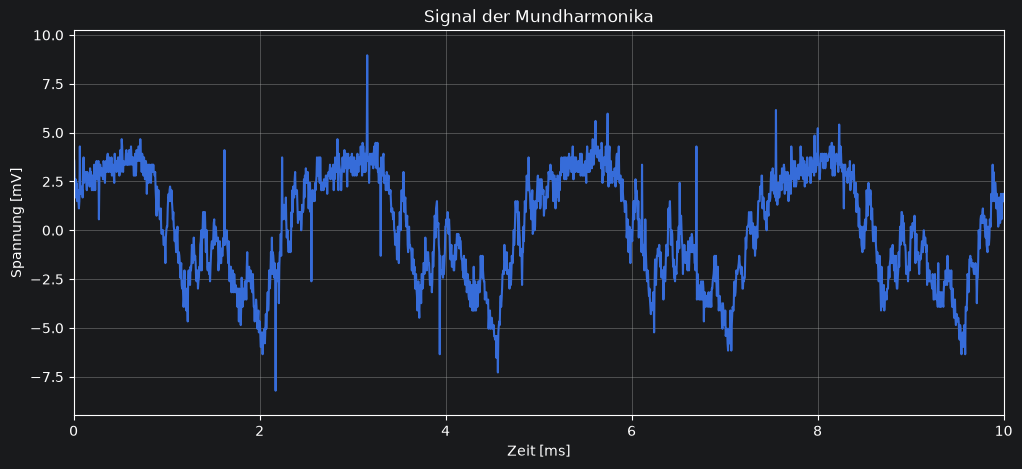

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(zeit, signal)

plt.xlabel("Zeit [ms]")
plt.ylabel("Spannung [mV]")
plt.title("Signal der Mundharmonika")
plt.grid()
plt.xlim(0, 10)
plt.show()

### Bestimmung der Grundperiode und Grundfrequenz


In [5]:
# Grundperiode in Sekunden
T0 = 2.5 / 1000

# Grundfrequenz
f0 = 1 / T0

print("Grundperiode:", T0 * 1000, "ms")
print("Grundfrequenz:", f0, "Hz")

Grundperiode: 2.5 ms
Grundfrequenz: 400.0 Hz


### Bestimmung der Signalparameter

Es werden die Signallänge M, das Abtastintervall,
die Abtastfrequenz und die Signaldauer bestimmt.

In [6]:
# Signallänge
M = len(signal)

# Abtastintervall in Sekunden
dt = np.mean(np.diff(zeit)) / 1000

# Abtastfrequenz
fs = 1 / dt

# Signaldauer
T = M * dt

print("Signallänge:", M)
print("Abtastintervall:", dt, "s")
print("Abtastfrequenz:", fs, "Hz")
print("Signaldauer:", T, "s")

Signallänge: 10004
Abtastintervall: 4.999999873038088e-06 s
Abtastfrequenz: 200000.00507847662 Hz
Signaldauer: 0.05001999872987303 s


### Fouriertransformation und Amplitudenspektrum

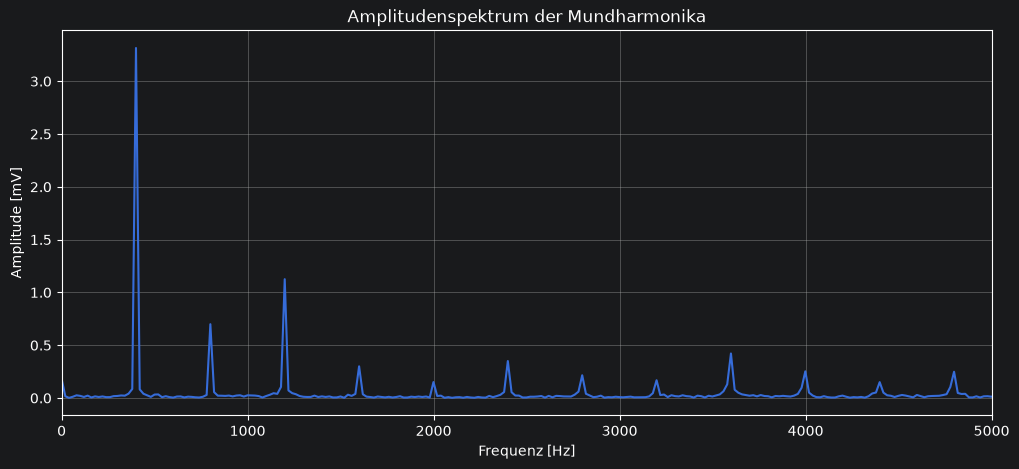

In [38]:
# Fouriertransformation
fourier = np.fft.fft(signal)

# Betrag der Fourier-Koeffizienten berechnen
amplitude = np.abs(fourier[:M//2])
# Amplituden verdoppeln und durch M normieren
amplitude = amplitude * 2 / M

# Amplitude bei 0 Hz korrigieren
amplitude[0] /= 2

# Frequenzachse in Hertz
frequenz = np.arange(len(amplitude)) / (M * dt)

plt.figure(figsize=(12, 5))

plt.plot(frequenz, amplitude)
plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude [mV]")
plt.title("Amplitudenspektrum der Mundharmonika")
plt.grid()
plt.xlim(0, 5000)
plt.show()

### Bestimmung der Grundfrequenz im Spektrum

Die Grundfrequenz wird im Amplitudenspektrum
identifiziert. Anschließend werden ihre Frequenz
und Amplitude bestimmt.

In [8]:
# Index der maximalen Amplitude (ohne Gleichanteil)
index = np.argmax(amplitude[1:]) + 1

# Dominante Frequenz und Amplitude
f0_fft = frequenz[index]
A0 = amplitude[index]

print("Frequenz:", f0_fft, "Hz")
print("Amplitude:", A0, "mV")

Frequenz: 399.8400741273023 Hz
Amplitude: 3.314505609656183 mV


## AUFGABE 2
### Darstellung des Sprachsignals

Als Sprachsignal wurde das russische Wort
„Privet“ (Hallo) aufgenommen.

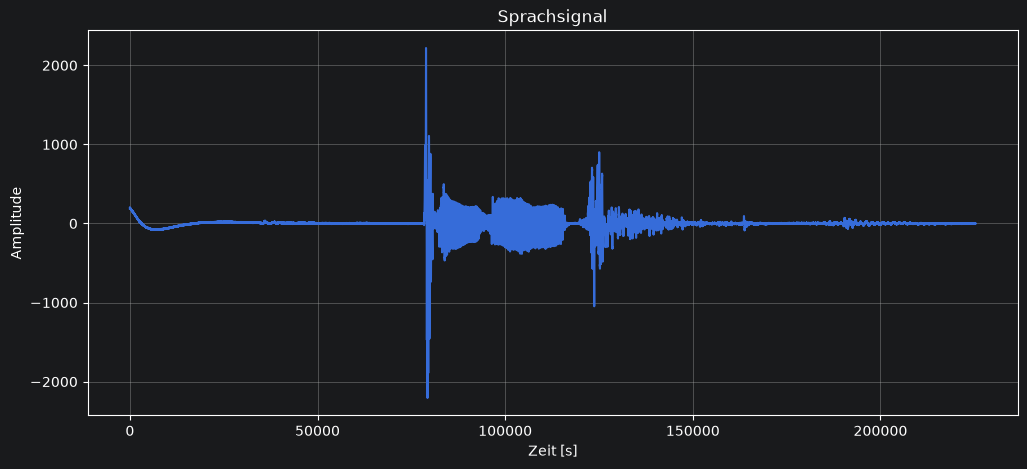

In [22]:
audio = np.load("data/audio.npy")

fs_audio = 44100
zeit_audio = np.arange(len(audio)) / fs_audio

plt.figure(figsize=(12, 5))
plt.plot(zeit_audio, audio)

plt.xlabel("Zeit [s]")
plt.ylabel("Amplitude")
plt.title("Sprachsignal")
plt.grid()
plt.show()

### Aufgabe 2b: Triggerfunktion

Der Beginn des Sprachsignals wird mithilfe
eines Schwellenwertes automatisch bestimmt.

In [32]:
def trigger(signal):
    # Schwellenwert für den Signalbeginn festlegen
    schwelle = 500

    # Anfang des Signals finden
    start = 0
    for i in range(len(signal)):
        # Prüfen, ob das Signal laut genug ist
        if abs(signal[i]) > schwelle:
            start = i
            break

    # Signal ab Triggerzeitpunkt ausschneiden
    signal = signal[start:]

    # Prüfen, ob das Signal kürzer als 1 Sekunde ist
    if len(signal) < fs_audio:
        # Fehlende Samples mit Nullen auffüllen
        signal = np.append(signal, np.zeros(fs_audio - len(signal)))
         # Signal auf 1 Sekunde kürzen
    signal = signal[:fs_audio]
    return signal

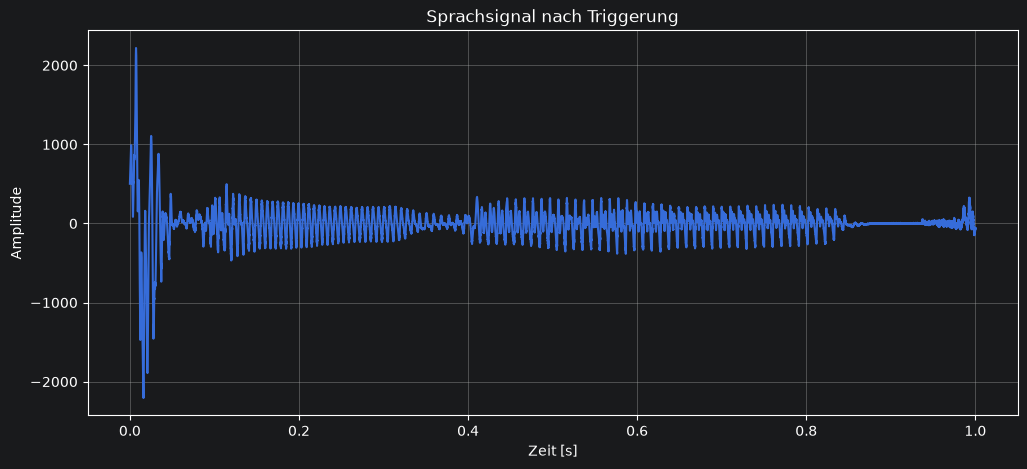

Signallänge: 44100
Signaldauer: 1.0 s


In [33]:
audio_trigger = trigger(audio)
zeit_trigger = np.arange(len(audio_trigger)) / fs_audio
plt.figure(figsize=(12, 5))
plt.plot(zeit_trigger, audio_trigger)

plt.xlabel("Zeit [s]")
plt.ylabel("Amplitude")
plt.title("Sprachsignal nach Triggerung")
plt.grid()
plt.show()

print("Signallänge:", len(audio_trigger))
print("Signaldauer:", len(audio_trigger) / fs_audio, "s")

### Aufgabe 2c: Amplitudenspektrum

Mithilfe der diskreten Fouriertransformation
wird das Amplitudenspektrum des getriggerten
Sprachsignals berechnet und dargestellt.

In [34]:
# Anzahl der Samples
M_audio = len(audio_trigger)

# Fouriertransformation
fourier = np.fft.fft(audio_trigger)

# Amplitudenspektrum berechnen
amplitude_audio = np.abs(fourier[:M//2]) * 2 / M
amplitude_audio[0] /= 2

# Frequenzachse berechnen
frequenz_audio = np.arange(M//2) * fs_audio / M

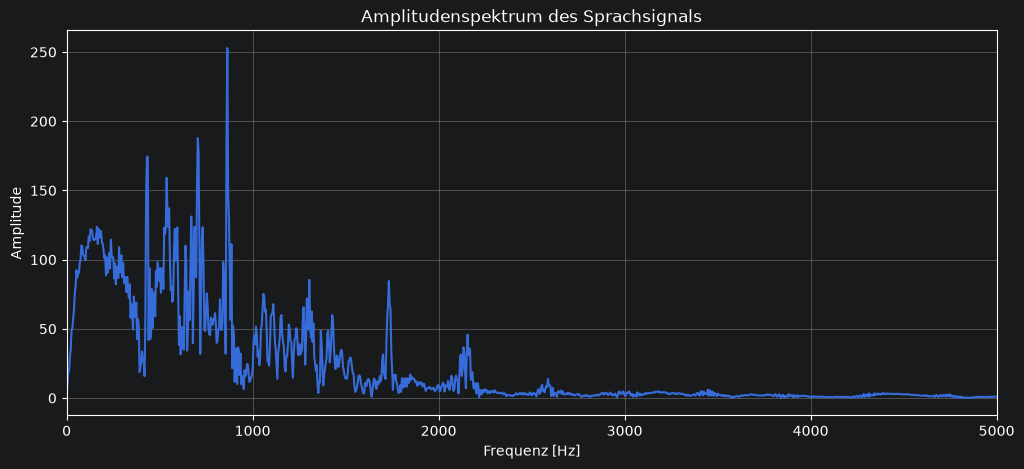

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(frequenz_audio, amplitude_audio)

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Amplitudenspektrum des Sprachsignals")

plt.xlim(0, 5000)
plt.grid()
plt.show()

### Aufgabe 2d: Windowing

Das Sprachsignal wird in Fenster mit einer Länge
von 512 Samples und einer Überlappung von 50 %
unterteilt.

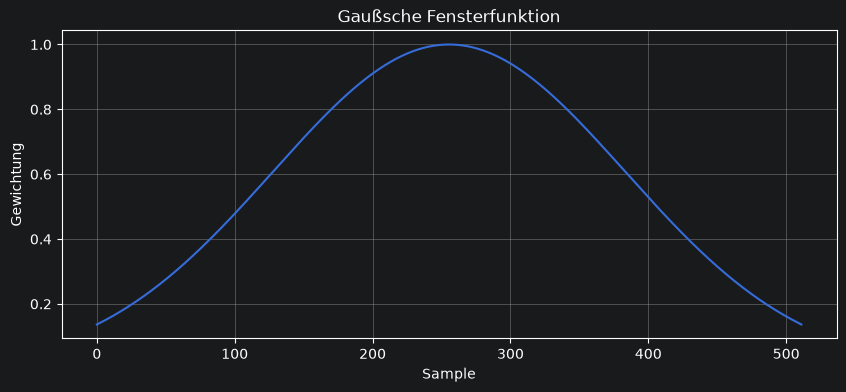

In [41]:
# Fenster Länge
N = 512

# Standardabweichung berechnen
sigma = N / 4

# Gaußsche Fensterfunktion erstellen
n = np.arange(N)
gauss = np.exp(-0.5 * ((n - (N - 1) / 2)/ sigma) ** 2)

plt.figure(figsize=(10, 4))
plt.plot(n, gauss)

plt.xlabel("Sample")
plt.ylabel("Gewichtung")
plt.title("Gaußsche Fensterfunktion")
plt.grid()
plt.show()

In [43]:
def windowing(signal, fs):
    # Schrittweite (50% Überlappung)
    step = 256
    leistungsspektren = []

    # Signal in Fenster aufteilen
    for start in range(0, len(signal) - N + 1, step):
        fenster = signal[start:start + N]

        # Gauß-Fenster anwenden
        fenster = fenster * gauss

        fourier = np.fft.fft(fenster)

        amplitude = 2 / np.sum(gauss) * np.abs(
            fourier[:N // 2]
        )

        amplitude[0] /= 2

        # Leistung berechnen
        leistung = amplitude**2

        leistungsspektren.append(leistung)

    mittlere_leistung = np.mean(leistungsspektren, axis=0)

    # Mittlere Amplitude berechnen
    amplitude = np.sqrt(mittlere_leistung)

    # Frequenzachse erstellen
    frequenz = np.arange(len(amplitude)) * fs / N

    return frequenz, amplitude

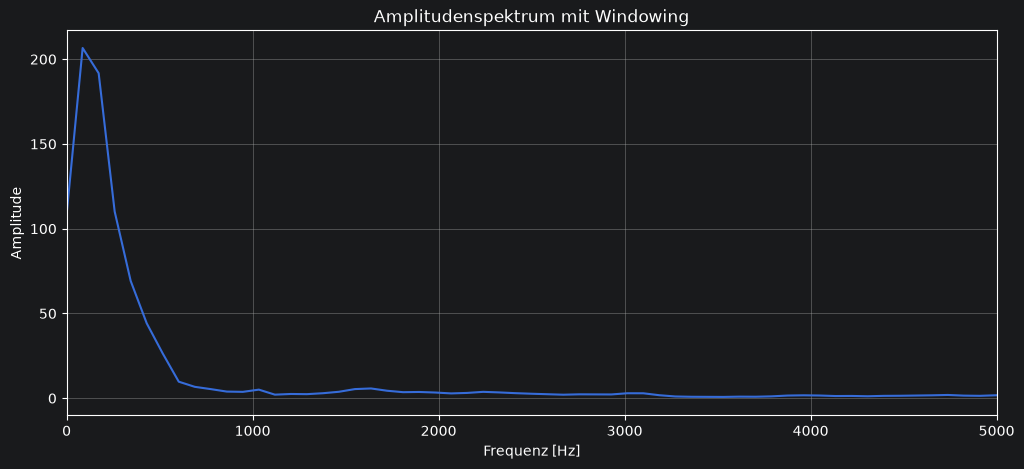

In [44]:
frequenz_window, amplitude_window = windowing(
    audio_trigger, fs_audio
)

plt.figure(figsize=(12, 5))

plt.plot(frequenz_window, amplitude_window)

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Amplitudenspektrum mit Windowing")

plt.xlim(0, 5000)
plt.grid()
plt.show()

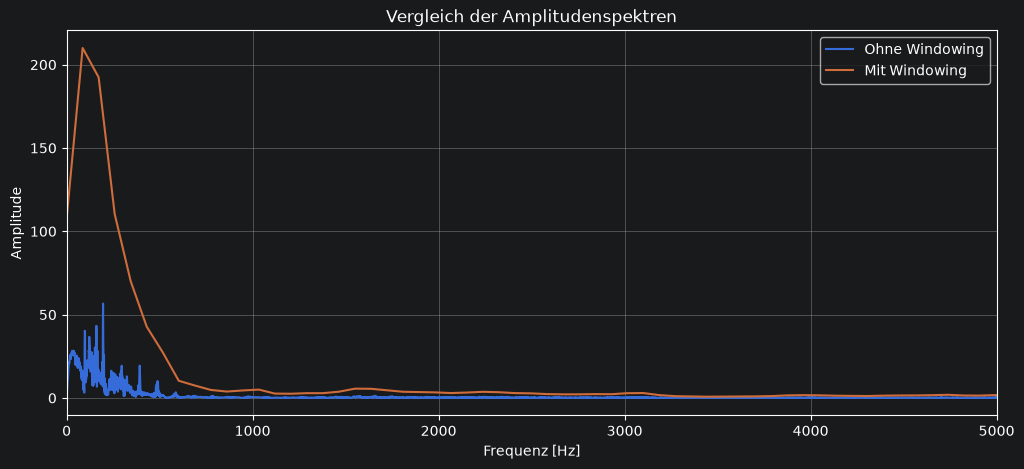

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(frequenz_audio, amplitude_audio,
         label="Ohne Windowing")

plt.plot(frequenz_window, amplitude_window,
         label="Mit Windowing")

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Vergleich der Amplitudenspektren")

plt.xlim(0, 5000)
plt.legend()
plt.grid()
plt.show()

### Aufgabe 3

Berechnung der Referenzspektren

In [45]:
befehle = ["Hoch","Tief","Links", "Rechts"]

# Referenzspektren speichern
referenzspektren = {}

for word in befehle:
    spektren = []
    for i in range(1,6):
        signal = np.load(f"data/Trainingsdaten/{word}_{i}.npy")

        # Trigger anwenden
        signal = trigger(signal)

        # Amplitudenspektrum berechnen
        frequenz, amplitude = windowing(signal, fs_audio)
        spektren.append(amplitude)

    # Mittelwert der fünf Spektren berechnen
    referenzspektren[word] = np.mean(spektren,axis=0)

Darstellung der Referenzspektren

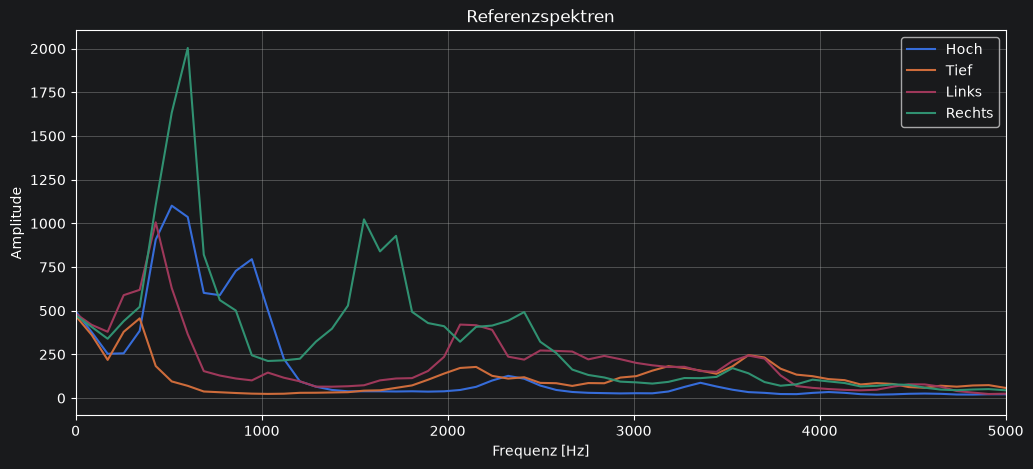

In [48]:
plt.figure(figsize=(12, 5))
for word in befehle:
    plt.plot(frequenz,referenzspektren[word], label=word)

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Referenzspektren")
plt.xlim(0, 5000)
plt.legend()
plt.grid()
plt.show()